# 01 · Data Explorer

Visualise the cleaned dataset cell by cell.

**Prerequisite:** the cleaned dataset must exist. If not, run from the repo root:
```
python3 -m src.convert all && python3 -m src.clean && python3 -m src.checks
```

| Section | What you get |
|---|---|
| 1 | Summary table of all 163 cells (split, policy, life, cleaning flags) |
| 2 | `plot_cell("b1c0")`: one-call dashboard for any cell |
| 3 | Interactive picker (dropdowns) |
| 4 | `compare_cells([...])`: overlay several cells |
| 5 | Gallery of every flagged cell (why each was flagged) |
| 6 | Whole-batch views: capacity curves, where glitches happen, ΔQ variance vs life |

**Cell naming:** `b1` = 2017-05-12, `b2` = 2017-06-30, `b3` = 2018-04-12 (paper's batches), `u1` = 2018-02-20 (unseen batch). Cycle numbers are always *real* cycle numbers (the off-by-one is handled by `curve()`).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm

from config import EOL_AH
from src.data import load_dataset, load_splits, curve, valid_cycle, row_of_cycle

%matplotlib inline
mpl.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "font.size": 9})
C1, C2, C3, C4, INK2, BAD = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#52514e", "#d03b3b"
BLUES = LinearSegmentedColormap.from_list("blues", ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#104281", "#0d366b"])

ds, sp = load_dataset(), load_splits()
cells, VDLIN = ds["cells"], ds["vdlin"]
SPLIT_OF = {c: k for k in ("train", "primary_test", "secondary_test", "unseen") for c in sp[k]}
BATCH_NAME = {"b1": "2017-05-12", "b2": "2017-06-30", "b3": "2018-04-12", "u1": "2018-02-20"}
print(f"{len(SPLIT_OF)} cells loaded:", {k: len(sp[k]) for k in ("train", "primary_test", "secondary_test", "unseen")})

163 cells loaded: {'train': 41, 'primary_test': 43, 'secondary_test': 40, 'unseen': 39}


## 1 · Summary table of every cell

In [2]:
def summary_row(cid):
    c = cells[cid]; s = c["summary"]
    early = (s["cycle"] >= 2) & (s["cycle"] <= 100)
    return {
        "cell": cid, "batch": BATCH_NAME[c["batch"]], "split": SPLIT_OF[cid],
        "policy": c["policy"], "cycle_life": int(c["cycle_life"]),
        "QD_cycle2": round(float(s["QD"][s["cycle"] == 2][0]), 4),
        "qd_glitches": c["n_qd_glitches"],
        "missing_IR_2_100": int(np.isnan(s["IR"][early]).sum()),
        "temp_swing_C": round(c["temp_swing"], 2),
        "temp_suspect": c["temp_suspect"],
        "anomalous": cid in sp["anomalous"],
        "newstructure": "newstructure" in c["policy"],
        "merged_from": c.get("merged_from", ""),
    }

df = pd.DataFrame([summary_row(c) for c in SPLIT_OF]).set_index("cell")
# natural sort: batch (b1, b2, b3, u1), then cell number (c2 before c10)
df = df.loc[sorted(df.index, key=lambda c: (c[:2], int(c.split("c")[1])))]
pd.set_option("display.max_rows", 200)
print(f"{len(df)} cells (scroll to see all). Look up one cell with  df.loc['b1c2']")
df

163 cells (scroll to see all). Look up one cell with  df.loc['b1c2']


,batch,split,policy,cycle_life,QD_cycle2,qd_glitches,missing_IR_2_100,temp_swing_C,temp_suspect,anomalous,newstructure,merged_from
cell,,,,,,,,,,,,
b1c0,2017-05-12,primary_test,3.6C(80%)-3.6C,1852,1.0707,18,0,6.03,False,False,False,b2c7
b1c1,2017-05-12,train,3.6C(80%)-3.6C,2160,1.0753,0,1,4.60,False,False,False,b2c8
b1c2,2017-05-12,primary_test,3.6C(80%)-3.6C,2237,1.0799,1,1,4.90,False,False,False,b2c9
b1c3,2017-05-12,train,4C(80%)-4C,1434,1.0797,0,1,1.28,True,False,False,b2c15
b1c4,2017-05-12,primary_test,4C(80%)-4C,1709,1.0784,0,1,4.89,False,False,False,b2c16
b1c5,2017-05-12,train,4.4C(80%)-4.4C,1074,1.0761,1,0,3.78,False,False,False,
b1c6,2017-05-12,primary_test,4.8C(80%)-4.8C,636,1.0758,0,1,6.04,False,False,False,
b1c7,2017-05-12,train,4.8C(80%)-4.8C,870,1.0939,0,1,5.74,False,False,False,
b1c9,2017-05-12,primary_test,5.4C(40%)-3.6C,1054,1.0830,0,0,5.71,False,False,False,


### Cells removed during cleaning
Not every cell ID appears above: 24 IDs were removed or merged. This table lists each one and the reason.

In [3]:
import pickle
from config import PROC_DIR
REASON = {
    **{k: "A1: test stopped before EOL (0.91-0.97 Ah), no label" for k in ["b1c8", "b1c10", "b1c12", "b1c13", "b1c22"]},
    **{k: f"A2: merged into {v} (same physical cell, continued testing)" for k, v in
       zip(["b2c7", "b2c8", "b2c9", "b2c15", "b2c16"], ["b1c0", "b1c1", "b1c2", "b1c3", "b1c4"])},
    **{k: "A3: noisy / faulty channel (authors' list)" for k in ["b3c2", "b3c37", "b3c42", "b3c43"]},
    **{k: "A3: never reaches EOL (life = NaN) + authors' list" for k in ["b3c23", "b3c32"]},
}
rows = []
for b in ["b1", "b2", "b3", "u1"]:
    raw = pickle.load(open(PROC_DIR / f"{b}_raw.pkl", "rb"))["cells"]
    for k, v in raw.items():
        if k not in cells:
            why = REASON.get(k, "special experiment (VarCharge / SLOWCYCLE), no cycle life")
            rows.append({"cell": k, "batch": BATCH_NAME[b], "policy": v["policy"],
                         "stored_life": v["cycle_life"], "reason": why})
removed = pd.DataFrame(rows).set_index("cell")
print(f"{len(removed)} removed/merged  +  {len(df)} kept  =  {len(removed) + len(df)} cell records in the raw files")
removed

24 removed/merged  +  163 kept  =  187 cell records in the raw files


,batch,policy,stored_life,reason
cell,,,,
b1c8,2017-05-12,5.4C(40%)-3.6C,879.0,"A1: test stopped before EOL (0.91-0.97 Ah), no..."
b1c10,2017-05-12,5.4C(50%)-3C,906.0,"A1: test stopped before EOL (0.91-0.97 Ah), no..."
b1c12,2017-05-12,5.4C(50%)-3.6C,902.0,"A1: test stopped before EOL (0.91-0.97 Ah), no..."
b1c13,2017-05-12,5.4C(50%)-3.6C,897.0,"A1: test stopped before EOL (0.91-0.97 Ah), no..."
b1c22,2017-05-12,6C(30%)-3.6C,891.0,"A1: test stopped before EOL (0.91-0.97 Ah), no..."
b2c7,2017-06-30,80%)-3.6C,663.0,"A2: merged into b1c0 (same physical cell, cont..."
b2c8,2017-06-30,80%)-3.6C,982.0,"A2: merged into b1c1 (same physical cell, cont..."
b2c9,2017-06-30,80%)-3.6C,1061.0,"A2: merged into b1c2 (same physical cell, cont..."
b2c15,2017-06-30,80%)-4C,209.0,"A2: merged into b1c3 (same physical cell, cont..."


In [4]:
# Quick filters - edit freely
print("Flagged cells:")
df[(df.qd_glitches > 0) | (df.missing_IR_2_100 > 0) | df.temp_suspect | df.anomalous | (df.merged_from != "")]

Flagged cells:


,batch,split,policy,cycle_life,QD_cycle2,qd_glitches,missing_IR_2_100,temp_swing_C,temp_suspect,anomalous,newstructure,merged_from
cell,,,,,,,,,,,,
b1c0,2017-05-12,primary_test,3.6C(80%)-3.6C,1852,1.0707,18,0,6.03,False,False,False,b2c7
b1c1,2017-05-12,train,3.6C(80%)-3.6C,2160,1.0753,0,1,4.60,False,False,False,b2c8
b1c2,2017-05-12,primary_test,3.6C(80%)-3.6C,2237,1.0799,1,1,4.90,False,False,False,b2c9
b1c3,2017-05-12,train,4C(80%)-4C,1434,1.0797,0,1,1.28,True,False,False,b2c15
b1c4,2017-05-12,primary_test,4C(80%)-4C,1709,1.0784,0,1,4.89,False,False,False,b2c16
b1c5,2017-05-12,train,4.4C(80%)-4.4C,1074,1.0761,1,0,3.78,False,False,False,
b1c6,2017-05-12,primary_test,4.8C(80%)-4.8C,636,1.0758,0,1,6.04,False,False,False,
b1c7,2017-05-12,train,4.8C(80%)-4.8C,870,1.0939,0,1,5.74,False,False,False,
b1c11,2017-05-12,train,5.4C(50%)-3C,788,1.0538,0,1,6.08,False,False,False,


In [5]:
df.groupby("split").cycle_life.describe().round(0)

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
primary_test,43.0,709.0,396.0,148.0,486.0,561.0,848.0,2237.0
secondary_test,40.0,1032.0,309.0,541.0,827.0,964.0,1123.0,1935.0
train,41.0,674.0,327.0,300.0,477.0,527.0,788.0,2160.0
unseen,39.0,566.0,222.0,392.0,440.0,472.0,508.0,1186.0


## 2 · One-call dashboard for a cell

`plot_cell(cell_id, cycles=(2, 10, 50, 100))` shows:
1. **Discharge capacity**: raw (red) vs cleaned (blue); removed glitches marked ×; EOL line and cycle life
2. **Internal resistance**: gaps = missing (NaN) values
3. **Temperature**: Tmin / Tavg / Tmax per cycle (a flat, narrow band = suspect probe)
4. **Charge time**
5. **Discharge curves Q(V)** at chosen cycles (a cycle with an invalid curve is replaced and labelled)
6. **dQ/dV** at the same cycles
7. **ΔQ₁₀₀₋₁₀(V)**, the paper's key feature, with its log-variance

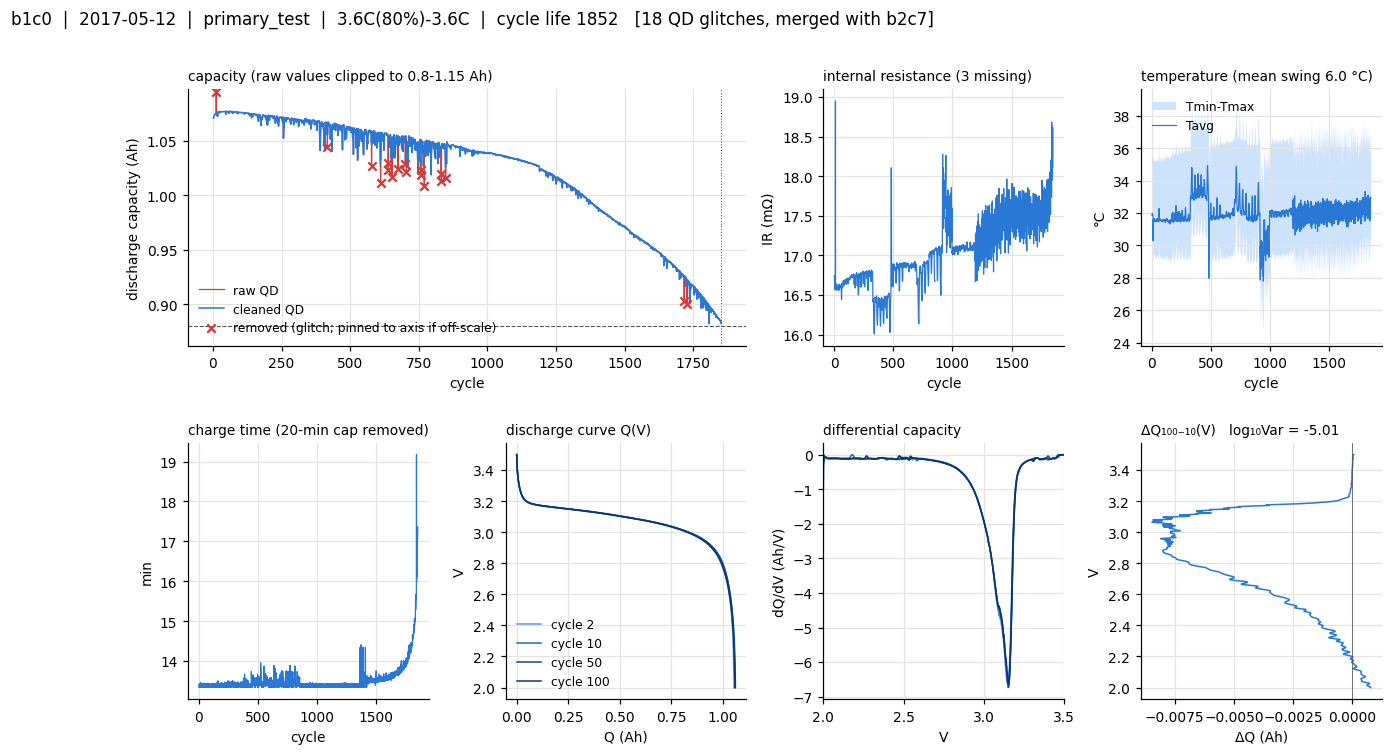

In [6]:
def plot_cell(cid, cycles=(2, 10, 50, 100), max_cycle=None):
    c = cells[cid]; s = c["summary"]; life = c["cycle_life"]
    cyc = s["cycle"]
    m = cyc <= (max_cycle or cyc.max())
    fig = plt.figure(figsize=(14, 7.2))
    gs = fig.add_gridspec(2, 4, hspace=0.38, wspace=0.32)
    flags = [f for f, on in [("ANOMALOUS", cid in sp["anomalous"]), ("TEMP-PROBE SUSPECT", c["temp_suspect"]),
                             (f"{c['n_qd_glitches']} QD glitches", c["n_qd_glitches"] > 0),
                             (f"merged with {c.get('merged_from')}", bool(c.get("merged_from")))] if on]
    fig.suptitle(f"{cid}  |  {BATCH_NAME[c['batch']]}  |  {SPLIT_OF[cid]}  |  {c['policy']}  |  "
                 f"cycle life {life:.0f}" + ("   [" + ", ".join(flags) + "]" if flags else ""),
                 x=0.01, ha="left", fontsize=11)
    # 1 capacity
    ax = fig.add_subplot(gs[0, 0:2])
    raw, clean = s["QD"], s["QD_clean"]
    ax.plot(cyc[m], raw[m], color=BAD, lw=0.8, label="raw QD")
    ax.plot(cyc[m], clean[m], color=C1, lw=1.0, label="cleaned QD")
    g = m & np.isnan(clean) & np.isfinite(raw)
    ylo, yhi = max(0.8, np.nanmin(clean[m]) - 0.02), min(1.15, np.nanmax(clean[m]) + 0.02)
    ax.scatter(cyc[g], np.clip(raw[g], ylo + 0.002, yhi - 0.002), marker="x", color=BAD, s=30, zorder=5,
               label="removed (glitch; pinned to axis if off-scale)")
    ax.axhline(EOL_AH, color=INK2, ls="--", lw=0.7); ax.axvline(life, color=INK2, ls=":", lw=0.7)
    ax.set_ylim(ylo, yhi)
    ax.set_xlabel("cycle"); ax.set_ylabel("discharge capacity (Ah)"); ax.legend(loc="lower left", fontsize=8)
    ax.set_title("capacity (raw values clipped to 0.8-1.15 Ah)", loc="left", fontsize=9)
    # 2 IR
    ax = fig.add_subplot(gs[0, 2])
    ax.plot(cyc[m], s["IR"][m] * 1e3, color=C1, lw=0.8)
    nmiss = int(np.isnan(s["IR"][m]).sum())
    ax.set_title(f"internal resistance ({nmiss} missing)", loc="left", fontsize=9)
    ax.set_xlabel("cycle"); ax.set_ylabel("IR (mΩ)")
    # 3 temperature
    ax = fig.add_subplot(gs[0, 3])
    ax.fill_between(cyc[m], s["Tmin"][m], s["Tmax"][m], color="#cde2fb", lw=0, label="Tmin-Tmax")
    ax.plot(cyc[m], s["Tavg"][m], color=C1, lw=0.8, label="Tavg")
    ax.set_title(f"temperature (mean swing {c['temp_swing']:.1f} °C)", loc="left", fontsize=9)
    ax.set_xlabel("cycle"); ax.set_ylabel("°C"); ax.legend(fontsize=8, loc="upper left")
    # 4 charge time
    ax = fig.add_subplot(gs[1, 0])
    ax.plot(cyc[m], s["chargetime"][m], color=C1, lw=0.8)
    ax.set_title("charge time (20-min cap removed)", loc="left", fontsize=9)
    ax.set_xlabel("cycle"); ax.set_ylabel("min")
    # 5/6 curves
    a5, a6 = fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[1, 2])
    cols = BLUES(np.linspace(0.25, 1, len(cycles)))
    for n, col in zip(cycles, cols):
        try:
            used = valid_cycle(c, n)
        except ValueError:
            continue
        lab = f"cycle {n}" + (f" (used {used})" if used != n else "")
        a5.plot(curve(c, "Qdlin", n), VDLIN, color=col, lw=1, label=lab)
        a6.plot(VDLIN, curve(c, "dQdV", n), color=col, lw=1)
    a5.set_xlabel("Q (Ah)"); a5.set_ylabel("V"); a5.legend(fontsize=8, loc="lower left")
    a5.set_title("discharge curve Q(V)", loc="left", fontsize=9)
    a6.set_xlabel("V"); a6.set_ylabel("dQ/dV (Ah/V)"); a6.set_xlim(2.0, 3.5)
    a6.set_title("differential capacity", loc="left", fontsize=9)
    # 7 delta Q
    ax = fig.add_subplot(gs[1, 3])
    dq = curve(c, "Qdlin", 100) - curve(c, "Qdlin", 10)
    ax.plot(dq, VDLIN, color=C1, lw=1); ax.axvline(0, color=INK2, lw=0.5)
    ax.set_title(f"ΔQ₁₀₀₋₁₀(V)   log₁₀Var = {np.log10(np.var(dq, ddof=1)):.2f}", loc="left", fontsize=9)
    ax.set_xlabel("ΔQ (Ah)"); ax.set_ylabel("V")
    plt.show()

plot_cell("b1c0")

## 3 · Interactive picker
Choose a split, then a cell. (Needs a running kernel; if widgets don't render, just call `plot_cell(...)` directly.)

In [7]:
import ipywidgets as w
from IPython.display import display

split_dd = w.Dropdown(options=["train", "primary_test", "secondary_test", "unseen"], description="split")
cell_dd = w.Dropdown(options=sp["train"], description="cell")
maxc = w.IntSlider(value=0, min=0, max=2300, step=50, description="max cycle", tooltip="0 = all")
out = w.Output()

def _cells_for(split):
    return sorted(sp[split], key=lambda c: cells[c]["cycle_life"])

def _label(cid):
    return f"{cid}  ({cells[cid]['cycle_life']:.0f} cyc, {cells[cid]['policy']})"

def _update_cells(change):
    cell_dd.options = [(_label(c), c) for c in _cells_for(split_dd.value)]

def _draw(change=None):
    out.clear_output(wait=True)
    with out:
        plot_cell(cell_dd.value, max_cycle=maxc.value or None)

split_dd.observe(_update_cells, "value"); cell_dd.observe(_draw, "value"); maxc.observe(_draw, "value")
_update_cells(None)
display(w.HBox([split_dd, cell_dd, maxc]), out)

Output()

## 4 · Compare several cells

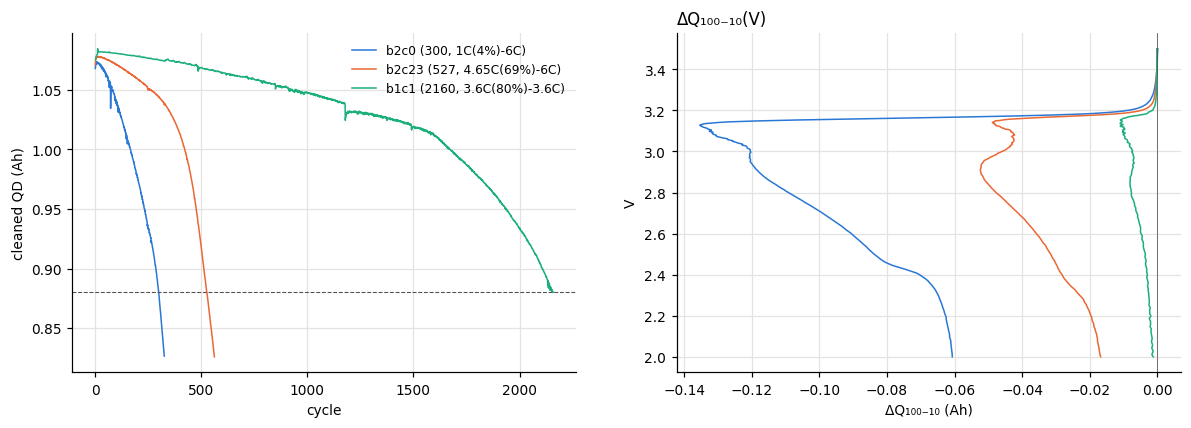

In [8]:
def compare_cells(cids, max_cycle=None):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    palette = [C1, C2, C3, C4, INK2, BAD]
    for cid, col in zip(cids, palette):
        c = cells[cid]; s = c["summary"]; m = s["cycle"] <= (max_cycle or 1e9)
        lab = f"{cid} ({c['cycle_life']:.0f}, {c['policy']})"
        a1.plot(s["cycle"][m], s["QD_clean"][m], color=col, lw=1, label=lab)
        dq = curve(c, "Qdlin", 100) - curve(c, "Qdlin", 10)
        a2.plot(dq, VDLIN, color=col, lw=1)
    a1.axhline(EOL_AH, color=INK2, ls="--", lw=0.7)
    a1.set_xlabel("cycle"); a1.set_ylabel("cleaned QD (Ah)"); a1.legend(fontsize=8)
    a2.axvline(0, color=INK2, lw=0.5); a2.set_xlabel("ΔQ₁₀₀₋₁₀ (Ah)"); a2.set_ylabel("V")
    a2.set_title("ΔQ₁₀₀₋₁₀(V)", loc="left")
    plt.show()

# shortest, median and longest cell in the training set
tr = sorted(sp["train"], key=lambda c: cells[c]["cycle_life"])
compare_cells([tr[0], tr[len(tr) // 2], tr[-1]])

policy: 5.3C(54%)-4C-newstructure | cells: ['b3c1', 'b3c9', 'b3c17', 'b3c25', 'b3c30', 'b3c34']


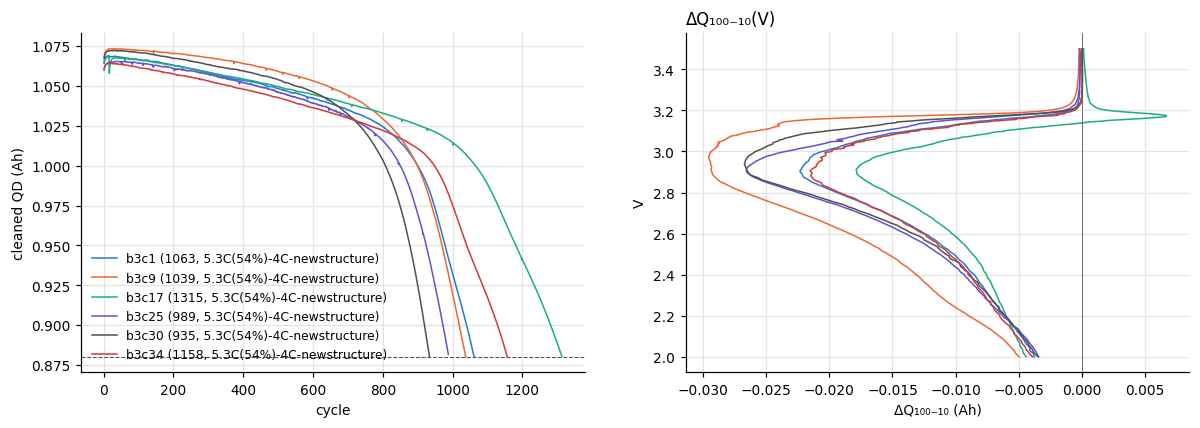

In [9]:
# Same policy, different lifetimes: cell-to-cell variation
pol = df[df.split != "unseen"].groupby("policy").size().sort_values(ascending=False).index[0]
same = df[(df.policy == pol) & (df.split != "unseen")].index.tolist()[:6]
print("policy:", pol, "| cells:", same)
compare_cells(same)

## 5 · Gallery of flagged cells
Each of these was flagged by a cleaning rule (see report, Table "Additional cleaning rules").


>>> b1c18: B3: capacity spike to 2.88 Ah at cycle 40


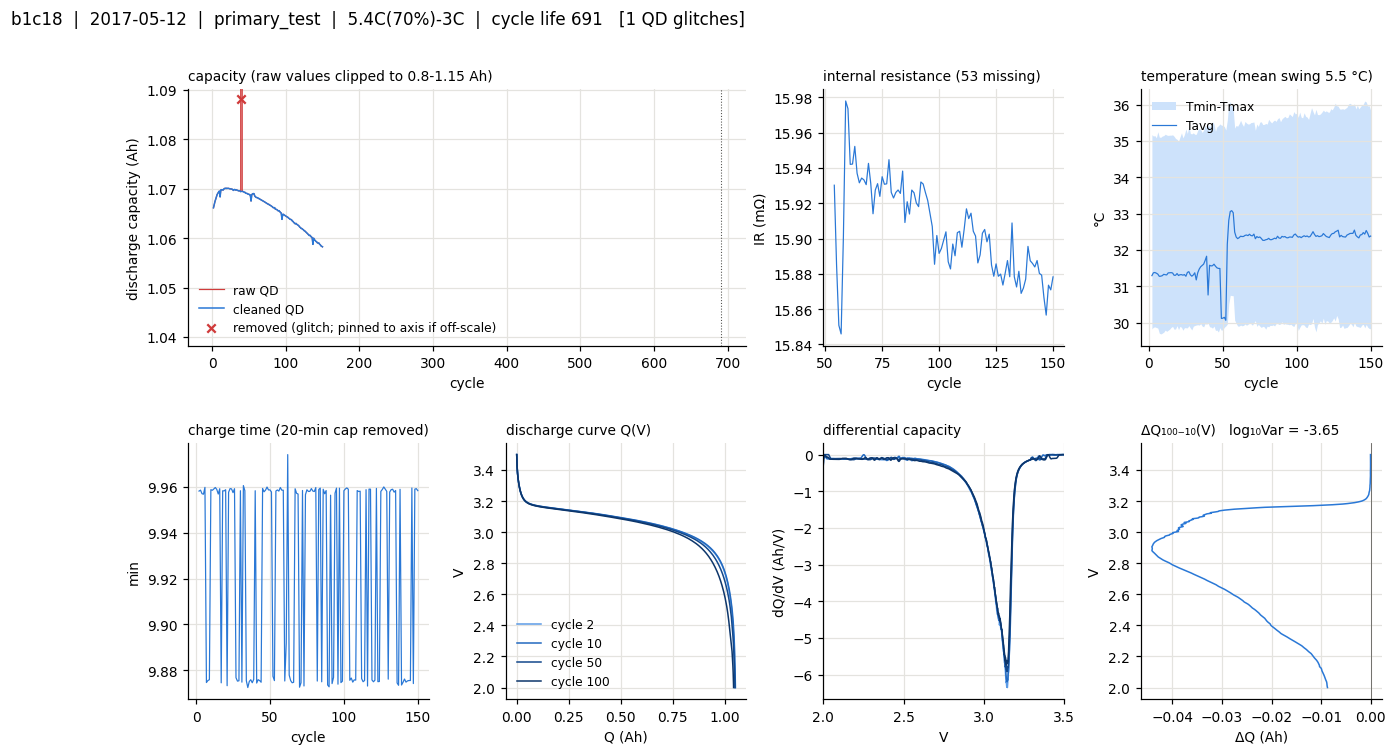


>>> b1c0: A2: joined with b2c7 (life 1190 -> 1852); B3: spike at cycle 12


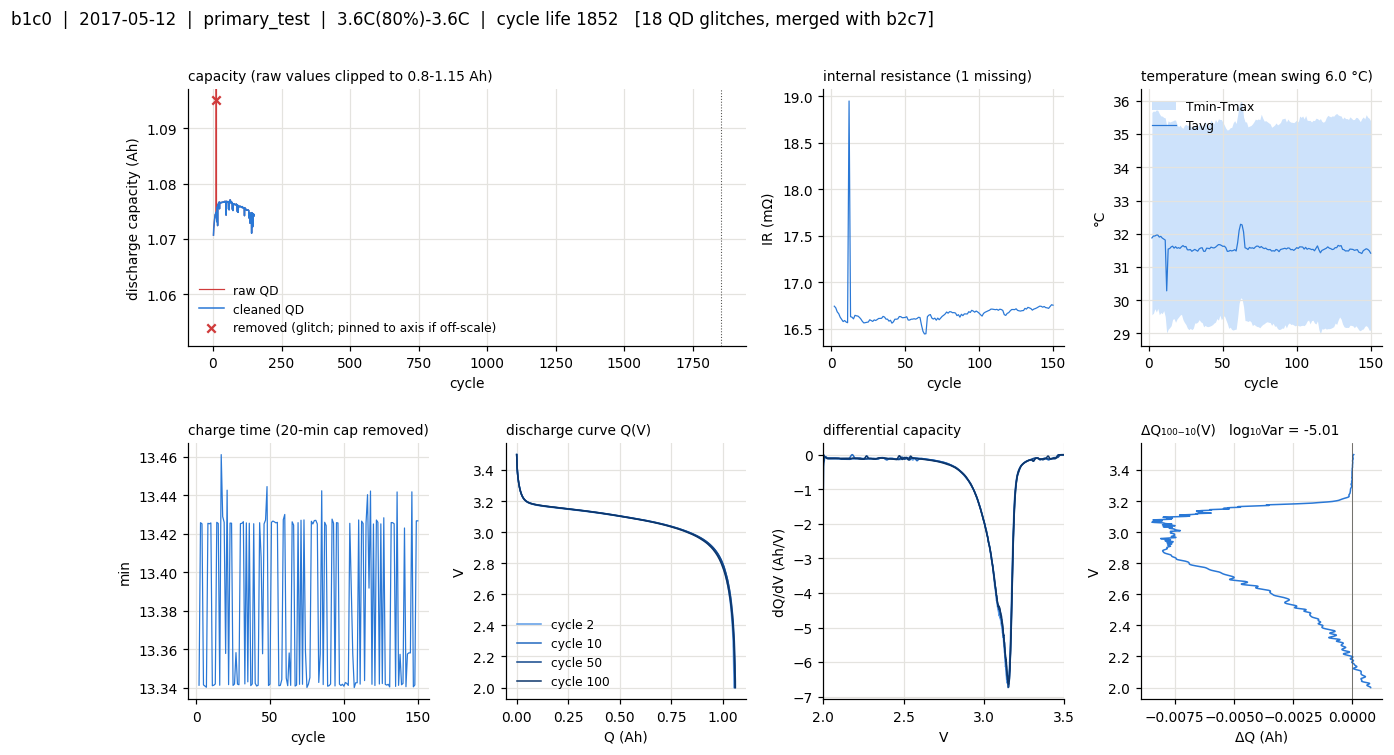


>>> u1c5: B3/B4: batch-wide dip at cycle 48 with a corrupt Q(V) curve


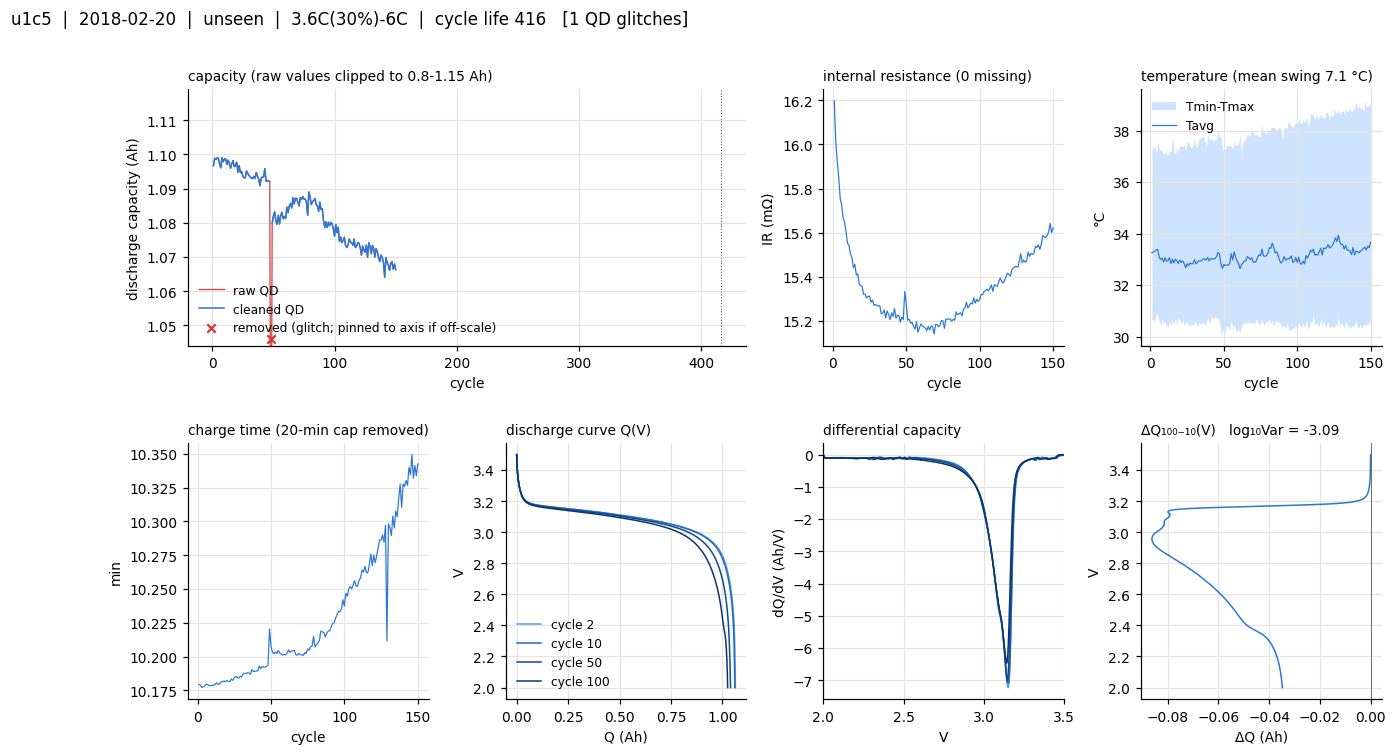


>>> u1c41: B2: no internal resistance recorded at all


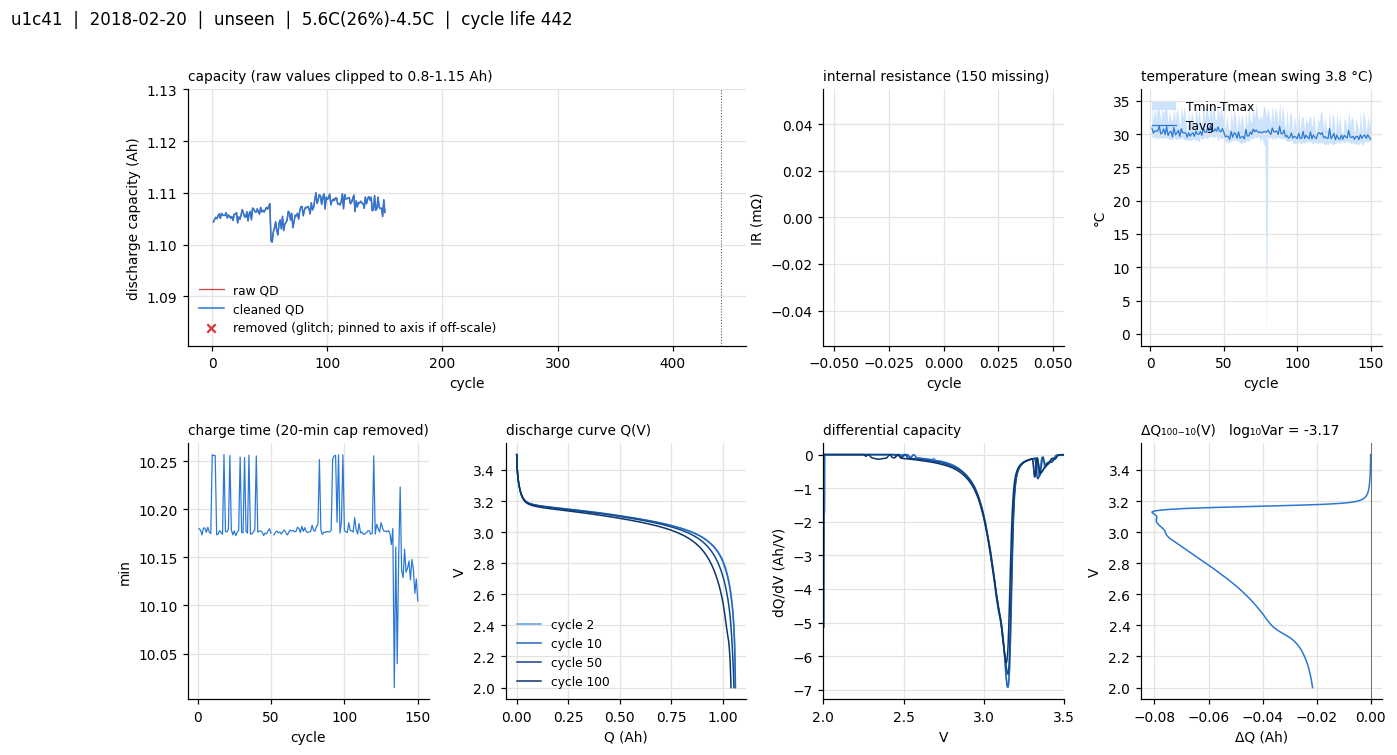


>>> b2c1: B8: anomalous early failure (148 cycles)


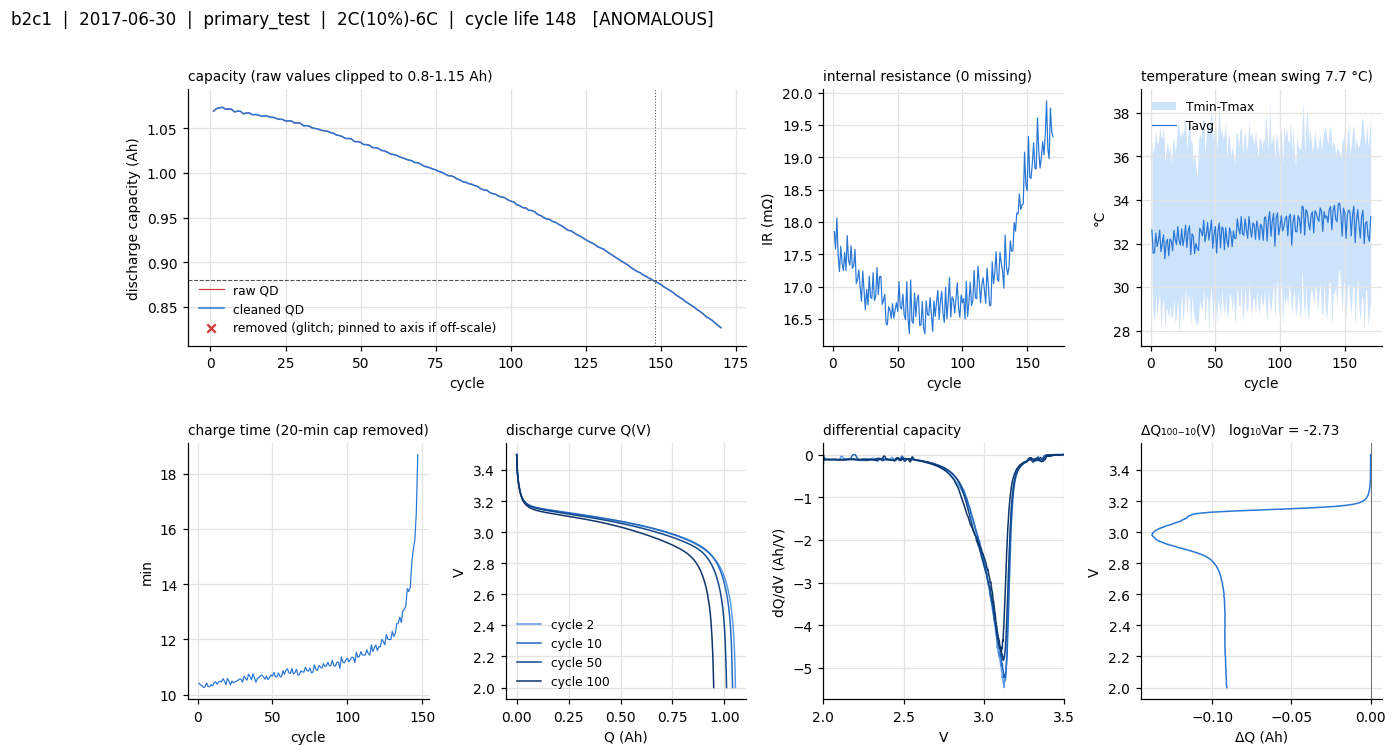


>>> b1c3: B6: suspected detached temperature probe


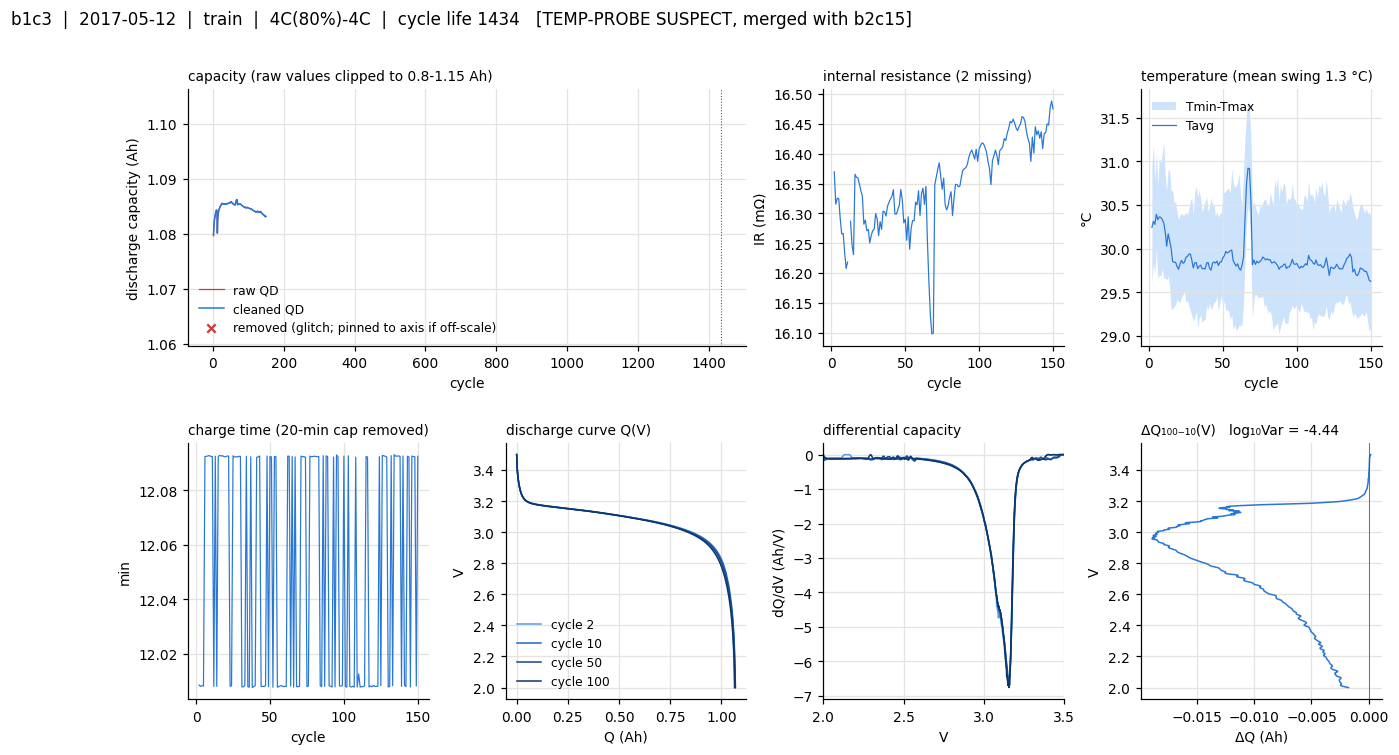


>>> b1c31: B6: suspected detached temperature probe


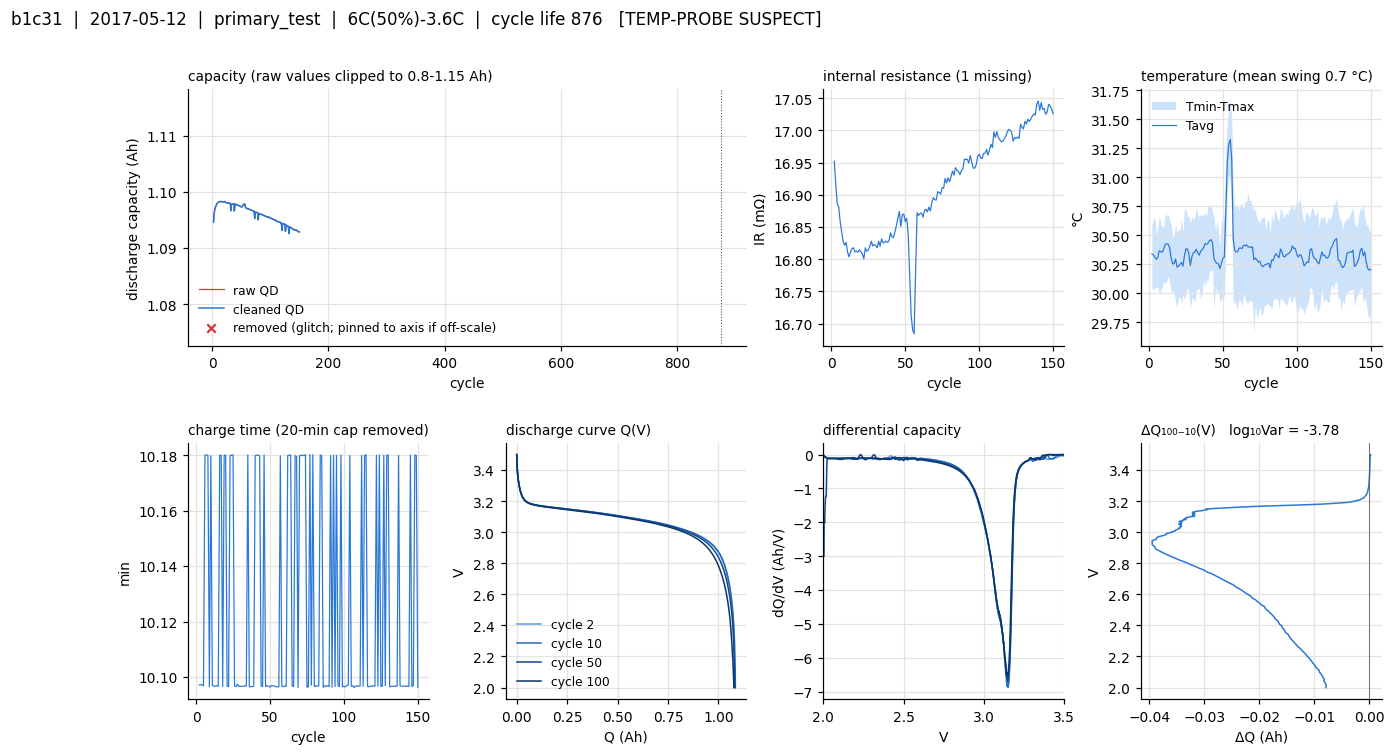


>>> b3c4: B6: suspected detached temperature probe


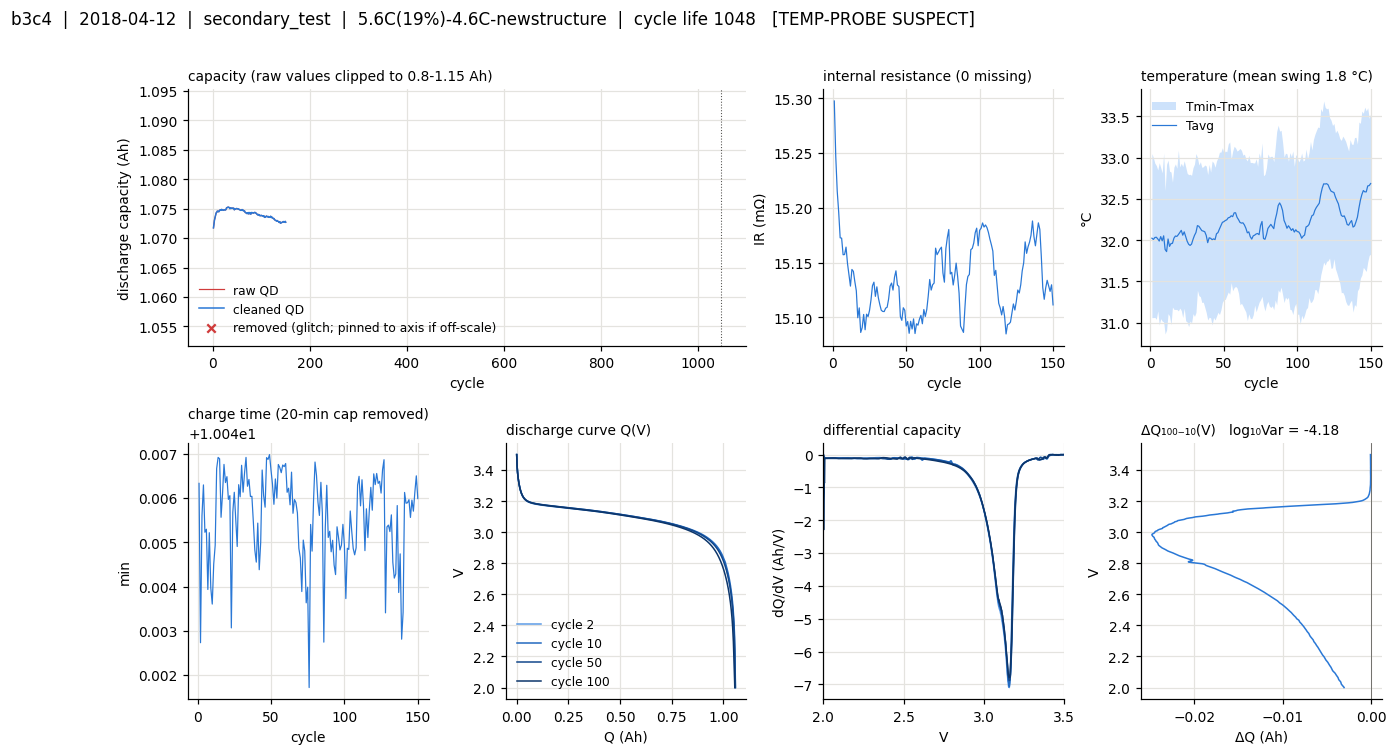


>>> b3c29: B6: suspected detached temperature probe


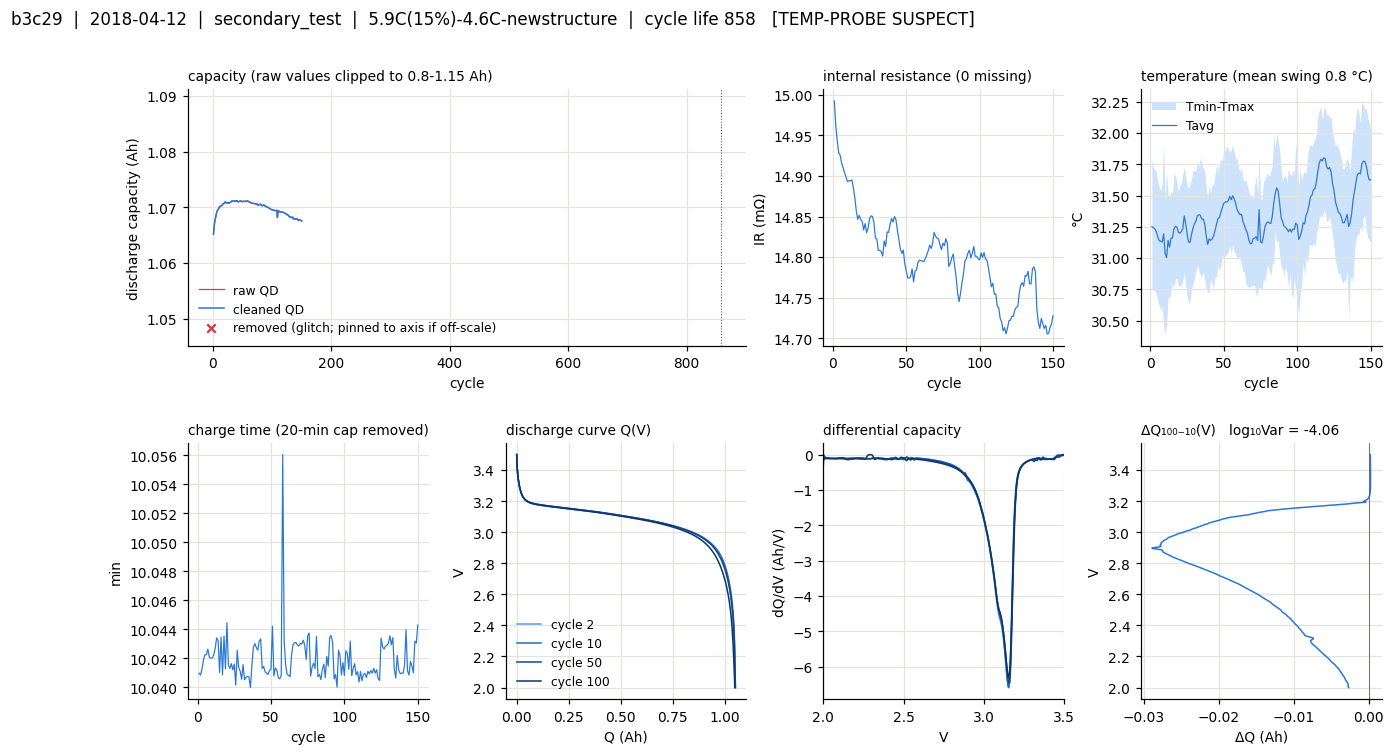

In [10]:
gallery = [
    ("b1c18", "B3: capacity spike to 2.88 Ah at cycle 40"),
    ("b1c0",  "A2: joined with b2c7 (life 1190 -> 1852); B3: spike at cycle 12"),
    ("u1c5",  "B3/B4: batch-wide dip at cycle 48 with a corrupt Q(V) curve"),
    ("u1c41", "B2: no internal resistance recorded at all"),
    ("b2c1",  "B8: anomalous early failure (148 cycles)"),
]
gallery += [(c, "B6: suspected detached temperature probe") for c in sp["temp_suspect"]]
for cid, why in gallery:
    print(f"\n>>> {cid}: {why}")
    plot_cell(cid, max_cycle=150 if not cid.startswith("b2c1") else None)

## 6 · Whole-batch views

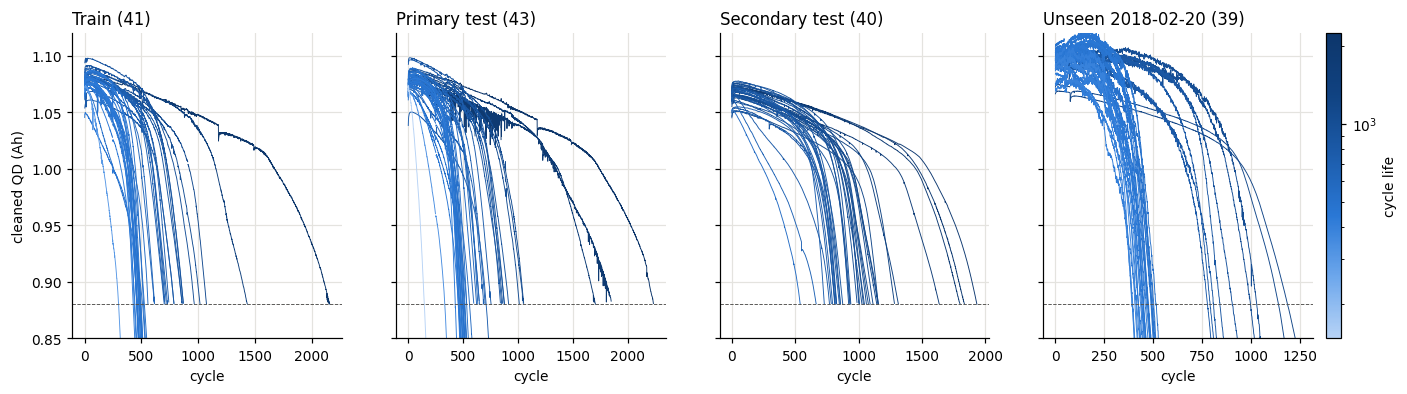

In [11]:
sets = [("train", "Train"), ("primary_test", "Primary test"), ("secondary_test", "Secondary test"), ("unseen", "Unseen 2018-02-20")]
L = [cells[c]["cycle_life"] for k, _ in sets for c in sp[k]]
norm = LogNorm(min(L), max(L))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (k, t) in zip(axes, sets):
    for cid in sorted(sp[k], key=lambda c: -cells[c]["cycle_life"]):
        s = cells[cid]["summary"]
        ax.plot(s["cycle"], s["QD_clean"], color=BLUES(norm(cells[cid]["cycle_life"])), lw=0.6)
    ax.axhline(EOL_AH, color=INK2, ls="--", lw=0.6); ax.set_title(f"{t} ({len(sp[k])})", loc="left")
    ax.set_xlabel("cycle"); ax.set_ylim(0.85, 1.12)
axes[0].set_ylabel("cleaned QD (Ah)")
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=BLUES), ax=axes, fraction=0.02, pad=0.01); cb.set_label("cycle life")
plt.show()

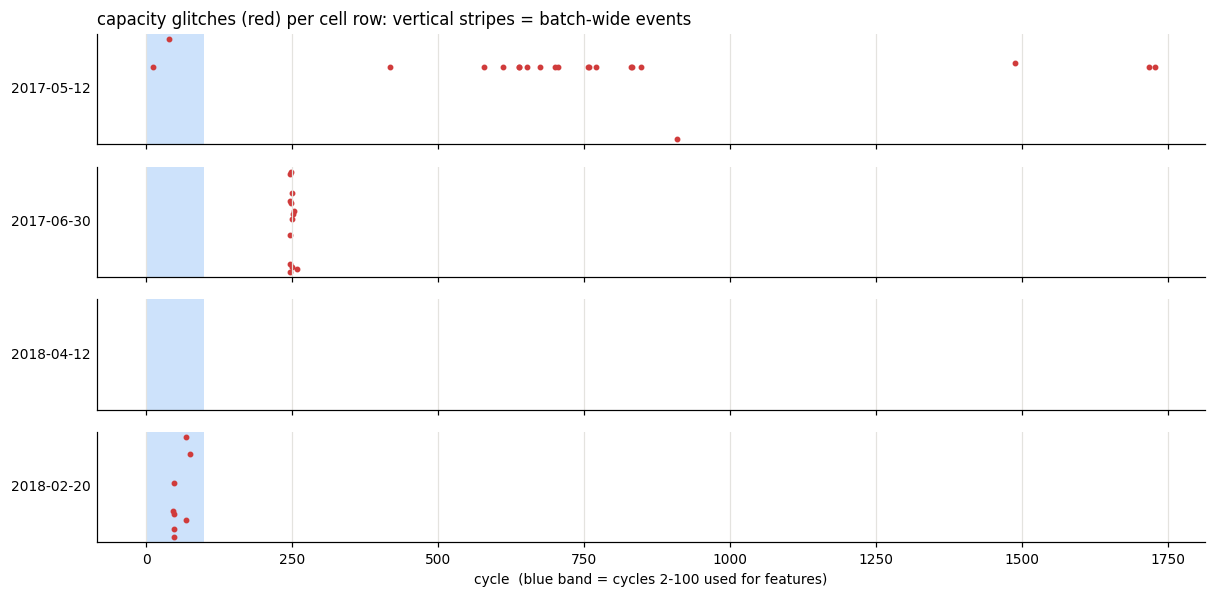

In [12]:
# Where do capacity glitches happen? (cycles flagged by rule B3, per batch)
fig, axes = plt.subplots(4, 1, figsize=(13, 6), sharex=True)
for ax, b in zip(axes, ["b1", "b2", "b3", "u1"]):
    ids = [c for c in SPLIT_OF if cells[c]["batch"] == b]
    for i, cid in enumerate(ids):
        s = cells[cid]["summary"]
        g = s["cycle"][np.isnan(s["QD_clean"]) & np.isfinite(s["QD"])]
        ax.scatter(g, np.full(len(g), i), s=8, color=BAD)
    ax.axvspan(2, 100, color="#cde2fb", lw=0, zorder=0)
    ax.set_ylabel(BATCH_NAME[b], rotation=0, ha="right", va="center"); ax.set_yticks([])
axes[-1].set_xlabel("cycle  (blue band = cycles 2-100 used for features)")
axes[0].set_title("capacity glitches (red) per cell row: vertical stripes = batch-wide events", loc="left")
plt.show()

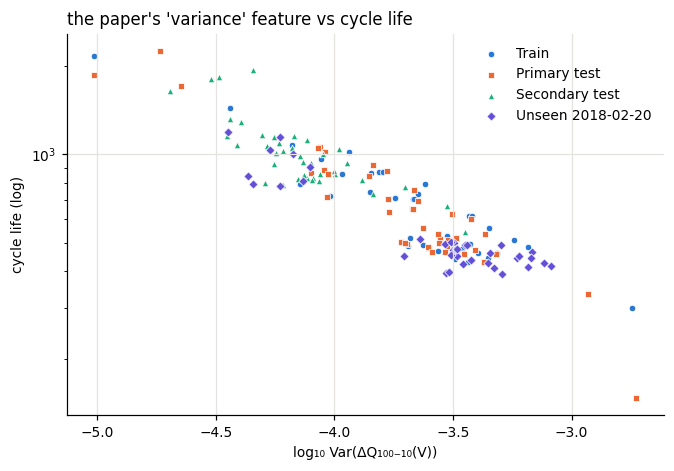

In [13]:
# Key feature vs label for all sets
fig, ax = plt.subplots(figsize=(7, 4.5))
for (k, t), col, mk in zip(sets, [C1, C2, C3, C4], ["o", "s", "^", "D"]):
    x = [np.log10(np.var(curve(cells[c], "Qdlin", 100) - curve(cells[c], "Qdlin", 10), ddof=1)) for c in sp[k]]
    y = [cells[c]["cycle_life"] for c in sp[k]]
    ax.scatter(x, y, s=18, color=col, marker=mk, edgecolor="white", lw=0.5, label=t)
ax.set_yscale("log"); ax.set_xlabel("log₁₀ Var(ΔQ₁₀₀₋₁₀(V))"); ax.set_ylabel("cycle life (log)")
ax.legend(); ax.set_title("the paper's 'variance' feature vs cycle life", loc="left")
plt.show()